# Issues with Marginal-Based Classification, or, Figure 2

In [9]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

import os
os.chdir('/content/drive/MyDrive/ve/variance_analysis')

from pathlib import Path
current_file_path = Path().resolve()

Mounted at /content/drive/


Obtaining file:///content/drive/MyDrive/ve/variance_analysis
  Preparing metadata (setup.py) ... done
  Attempting uninstall: variance_analysis
    Found existing installation: variance_analysis 0.1.0
    Uninstalling variance_analysis-0.1.0:
      Successfully uninstalled variance_analysis-0.1.0
  Running setup.py develop for variance_analysis
ERROR: specify a font number between 0 and 5 (inclusive)
Dumping "fonts/Helvetica.ttc" to "/usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf"...
Dumping 'GlyphOrder' table...
Dumping 'head' table...
Dumping 'hhea' table...
Dumping 'maxp' table...
Dumping 'OS/2' table...
Dumping 'hmtx' table...
Dumping 'hdmx' table...
Dumping 'cmap' table...
Dumping 'fpgm' table...
Dumping 'prep' table...
Dumping 'cvt ' table...
Dumping 'loca' table...
Dumping 'glyf' table...
Dumping 'kern' table...
Dumping 'name' table...
Dumping 'post' table...
Dumping 'Zapf' table...
Dumping 'feat' table...
Dumping 'meta' table...
Dumping 'morx' table...
Dumping 'prop'

/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/helvetica: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 16 fonts, 0 dirs
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/root/.local/share/fonts: skipping, no such directory
/root/.fonts: caching, new cache contents: 6 fonts, 0 dirs
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/helvetica: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/var/cache/fontconfig: cleaning cache directory
/root/.cache/fontconfig: not cleaning non-existent cache directory
/root/.fontconfig: not cleaning non

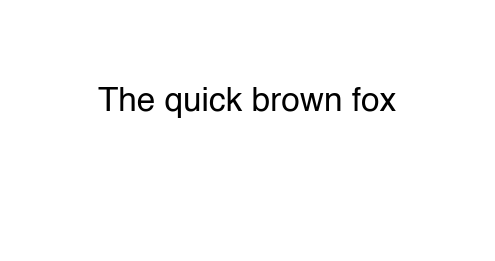

In [10]:
!pip install -e /content/drive/MyDrive/ve/variance_analysis

!pip -q install fonttools

!ttx -l fonts/Helvetica.ttc

!sudo mkdir -p /usr/share/fonts/truetype/helvetica
!ttx -y 0 -o /usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf fonts/Helvetica.ttc
!ttx -y 1 -o /usr/share/fonts/truetype/helvetica/Helvetica-Oblique.ttf fonts/Helvetica.ttc
!ttx -y 2 -o /usr/share/fonts/truetype/helvetica/Helvetica-Bold.ttf fonts/Helvetica.ttc
!ttx -y 3 -o /usr/share/fonts/truetype/helvetica/Helvetica-BoldOblique.ttf fonts/Helvetica.ttc

!mkdir -p ~/.fonts
!cp fonts/Helvetica.ttc ~/.fonts/

import matplotlib.font_manager as fm
import shutil
import matplotlib.pyplot as plt

cache_dir = os.path.join(os.path.expanduser("~"), ".cache", "matplotlib")
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

fm._load_fontmanager(try_read_cache=False)
plt.rcParams['font.family'] = 'Helvetica'

!fc-cache -fv

fig, ax = plt.subplots(figsize=(4, 2), dpi=150)
ax.text(0.5, 0.62, 'The quick brown fox', ha='center', va='center', fontsize=16)
ax.axis('off')
plt.show()

In [11]:
import numpy as np

np.random.seed(42)
SIGMA_X     = 1.0                       # width of the Gaussian tuning
PEAK_RATE   = 1.0                       # <- stays in arbitrary units
N_SAMPLES   = 300
CORR_LEVELS = [0.0, 0.6, 0.9]
Y_BINS      = 30
GRID_LIM    = 4.0

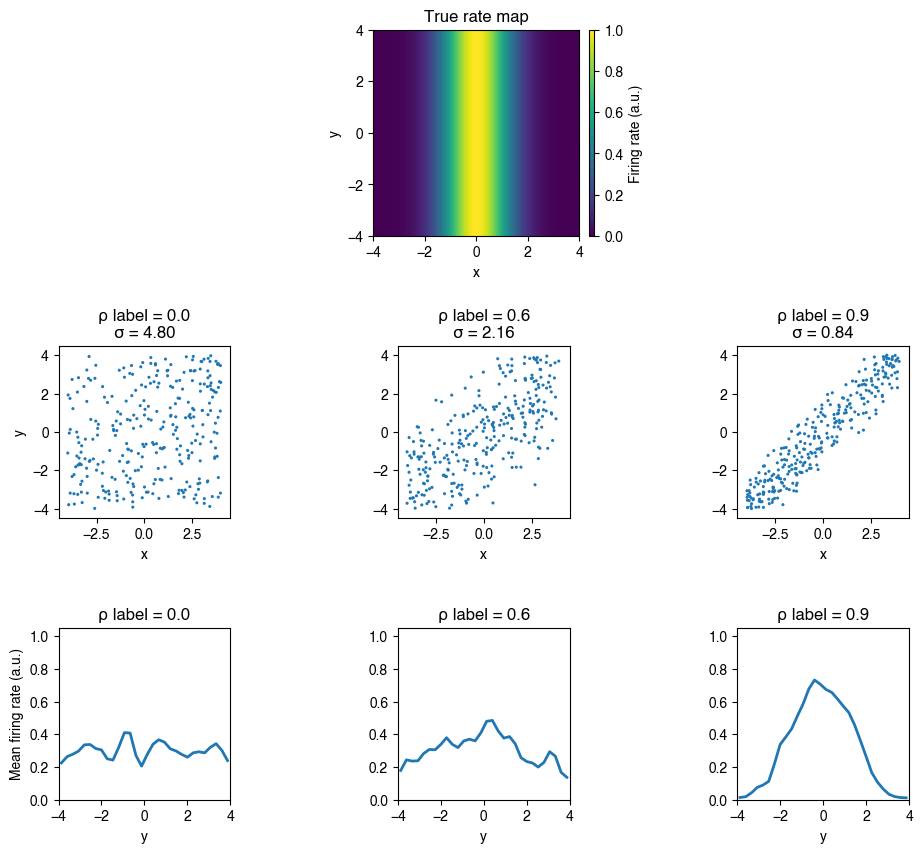

In [12]:
import numpy as np
from matplotlib import gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.ndimage import gaussian_filter1d

def firing_rate(x, y):
    return PEAK_RATE * np.exp(-0.5 * (x / SIGMA_X) ** 2)

def sample_uniform_then_trunc_normal(n, lim, sigma, rng=None):
    """
    Sample sx ~ Uniform[-lim, lim]
    Sample sy ~ Normal(mean=sx, std=sigma) truncated to [-lim, lim]
    Uses simple rejection sampling; efficient for your n=150.
    """
    if rng is None:
        rng = np.random.default_rng()

    sx = rng.uniform(-lim, lim, size=n)
    sy = np.empty(n, dtype=float)

    # rejection sampling for truncation
    for i in range(n):
        while True:
            y = rng.normal(loc=sx[i], scale=sigma)
            if -lim <= y <= lim:
                sy[i] = y
                break
    return sx, sy

fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(
    nrows=3,
    ncols=3,
    height_ratios=[1.2, 1.0, 1.0],
    hspace=0.4,
    wspace=0.35,
)
gs.update(hspace=0.60)

ROW_TITLES = ["", "Sampling schemes", "Apparent tuning curves"]  # row labels

# true rate map
ax_rate = fig.add_subplot(gs[0, :])
ax_rate.set_box_aspect(1)  # square axes box (you said this looks fine)

grid = np.linspace(-GRID_LIM, GRID_LIM, 200)
rate_map = firing_rate(*np.meshgrid(grid, grid))
im = ax_rate.imshow(
    rate_map,
    extent=[-GRID_LIM, GRID_LIM, -GRID_LIM, GRID_LIM],
    origin="lower",
    cmap="viridis",
    aspect="equal",
    vmin=0, vmax=PEAK_RATE,
)

divider = make_axes_locatable(ax_rate)
cax = divider.append_axes("right", size="2.5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Firing rate (a.u.)")

ax_rate.set_xlabel("x")
ax_rate.set_ylabel("y")
ax_rate.set_anchor("C")
ax_rate.set_title("True rate map")

# Map "rho labels" -> conditional width.
# Smaller sigma => tighter around y=x => higher correlation.
# (This is monotonic and intuitive; doesn’t require matching exact Pearson rho.)
min_sigma = 0.10 * GRID_LIM
max_sigma = 1.20 * GRID_LIM

rng = np.random.default_rng(0)  # optional: reproducibility

for idx, rho in enumerate(CORR_LEVELS):
    # convert rho in [0,1] into sigma in [max_sigma, min_sigma]
    # rho=0 -> widest (weak coupling), rho=1 -> tightest (strong coupling)
    sigma_cond = max_sigma * (1.0 - rho) + min_sigma * rho

    # NEW sampling scheme: uniform x coverage + correlated y
    sx, sy = sample_uniform_then_trunc_normal(N_SAMPLES, GRID_LIM, sigma_cond, rng=rng)
    fr = firing_rate(sx, sy)

    # sampling scatter plot
    ax_samp = fig.add_subplot(gs[1, idx])
    ax_samp.scatter(sx, sy, s=5, alpha=1.0, edgecolors="none")
    pad = 0.06 * (2 * GRID_LIM)
    ax_samp.set_xlim(-GRID_LIM - pad, GRID_LIM + pad)
    ax_samp.set_ylim(-GRID_LIM - pad, GRID_LIM + pad)
    #ax_samp.set_xlim(-GRID_LIM, GRID_LIM)
    #ax_samp.set_ylim(-GRID_LIM, GRID_LIM)
    ax_samp.set_xlabel("x")
    if idx == 0:
        ax_samp.set_ylabel("y")

    # Make the subplot itself square + equal data scaling
    ax_samp.set_box_aspect(1)
    #ax_samp.set_aspect("equal", adjustable="box")

    ax_samp.set_title(f"ρ label = {rho:.1f}\nσ = {sigma_cond:.2f}")

    # marginal tuning (same as before)
    bin_edges = np.linspace(-GRID_LIM, GRID_LIM, Y_BINS + 1)
    y_idx = np.digitize(sy, bin_edges) - 1
    y_idx = np.clip(y_idx, 0, Y_BINS - 1)

    rate_sums = np.zeros(Y_BINS, dtype=float)
    counts = np.zeros(Y_BINS, dtype=int)
    np.add.at(rate_sums, y_idx, fr)
    np.add.at(counts,   y_idx, 1)

    sigma_smooth = 1
    sm_sum = gaussian_filter1d(rate_sums, sigma=sigma_smooth, mode="nearest")
    sm_counts = gaussian_filter1d(counts.astype(float), sigma=sigma_smooth, mode="nearest")

    with np.errstate(divide="ignore", invalid="ignore"):
        sm_rates = np.divide(sm_sum, sm_counts, where=sm_counts > 0)

    MIN_COUNT = 5
    sm_rates[sm_counts < MIN_COUNT] = np.nan

    # plot
    bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    ax_marg = fig.add_subplot(gs[2, idx])
    ax_marg.plot(bin_centres, sm_rates, lw=2)
    ax_marg.set_xlim(-GRID_LIM, GRID_LIM)
    ax_marg.set_ylim(0, PEAK_RATE * 1.05)
    ax_marg.set_xlabel("y")
    if idx == 0:
        ax_marg.set_ylabel("Mean firing rate (a.u.)")

    # Make marginal panel square (panel geometry). Data aspect stays default.
    ax_marg.set_box_aspect(1)

    ax_marg.set_title(f"ρ label = {rho:.1f}")

fig.savefig(current_file_path / "figs/fig2.pdf")

In [13]:
from google.colab import output

output.eval_js('new Audio("https://upload.wikimedia.org/wikipedia/commons/d/d9/Wilhelm_Scream.ogg").play()')